In [1]:
import numpy as np
import pandas as pd
import time
# import kagglehub

In [2]:
# path = kagglehub.dataset_download("akram24/social-network-ads")
# print("Path to dataset files:", path)

In [3]:
import Dataset as ds
from pathlib import Path
current_file = Path.cwd()

In [5]:
df = pd.read_csv( current_file / "Dataset" / "Social_Network_Ads.csv")

In [5]:
np.shape(df)

(400, 5)

In [6]:
df = df[['Age','EstimatedSalary','Purchased']]

In [7]:
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [8]:
X = df.iloc[:,0:2]
y = df.iloc[:,-1]

In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [10]:
#from sklearn.model_selection import train_test_split
#X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [11]:
X_scaled.shape

(400, 2)

In [12]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [13]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(10,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

d:\Notes of CampusX\DL with CampusX\.dlenv\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 151 (604.00 B)

 Trainable params: 151 (604.00 B)

 Non-trainable params: 0 (0.00 B)

# Stochastic Gradient Descent 

In [15]:
model.compile(loss='binary_crossentropy',metrics=['accuracy'])
#start = time.time()
history = model.fit(X_scaled,y,epochs=10,batch_size=1,validation_split=0.2)
#print(time.time() - start)

Epoch 1/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7125 - loss: 0.6488 - val_accuracy: 0.3625 - val_loss: 0.7746
Epoch 2/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7125 - loss: 0.4771 - val_accuracy: 0.3625 - val_loss: 0.7103
Epoch 3/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 972us/step - accuracy: 0.7125 - loss: 0.4094 - val_accuracy: 0.3625 - val_loss: 0.6691
Epoch 4/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7750 - loss: 0.3788 - val_accuracy: 0.6250 - val_loss: 0.6215
Epoch 5/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8438 - loss: 0.3524 - val_accuracy: 0.6750 - val_loss: 0.5973
Epoch 6/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8500 - loss: 0.3418 - val_accuracy: 0.7625 - val_loss: 0.5422
Epoch 7/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8562 - loss: 0.3311 - val_accuracy: 0.8625 - val_loss: 0.5055
Epoch 8/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 980us/step - accuracy: 0.8687 - loss: 0.3141 - val_accuracy

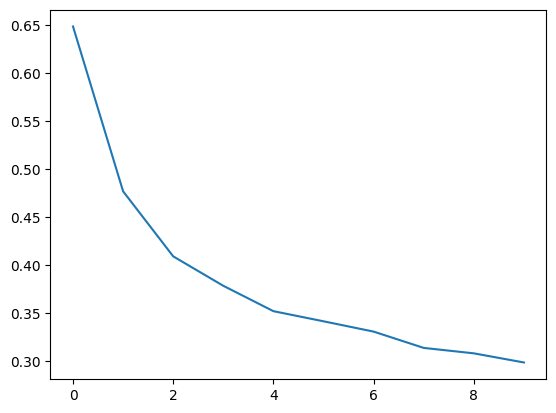

In [16]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])

# Batch Gradient Decent  

In [17]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(10,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [20]:
model.compile(loss='binary_crossentropy',metrics=['accuracy'])
#start = time.time()
history = model.fit(X_scaled,y,epochs=1000,batch_size=400,validation_split=0.2)
#print(time.time() - start)

Epoch 1/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 476ms/step - accuracy: 0.3562 - loss: 0.7387 - val_accuracy: 0.8625 - val_loss: 0.6590
Epoch 2/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.3906 - loss: 0.7309 - val_accuracy: 0.8625 - val_loss: 0.6590
Epoch 3/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.4375 - loss: 0.7257 - val_accuracy: 0.8875 - val_loss: 0.6589
Epoch 4/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.4500 - loss: 0.7214 - val_accuracy: 0.9000 - val_loss: 0.6589
Epoch 5/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.4563 - loss: 0.7178 - val_accuracy: 0.9000 - val_loss: 0.6588
Epoch 6/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.4688 - loss: 0.7145 - val_accuracy: 0.9375 - val_loss: 0.6586
Epoch 7/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.4844 - loss: 0.7114 - val_accuracy: 0.9375 - val_loss: 0.6585
Epoch 8/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.4906 - loss: 0.7086 - val_accuracy: 0.9375 - 

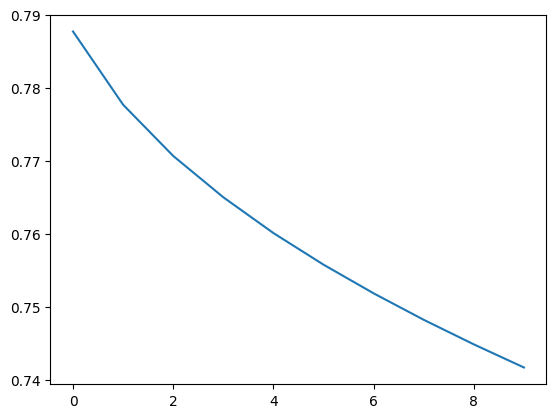

In [19]:
plt.plot(history.history['loss'])